In [2]:
from typing import TypedDict
from langgraph.graph import START, StateGraph, END
from langchain_groq import ChatGroq
from dotenv import load_dotenv
load_dotenv()

/home/dark/.local/share/mamba/envs/agentic_ai/lib/python3.12/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


True

In [11]:
llm = ChatGroq(model='openai/gpt-oss-20b', temperature=1)
llm_content = ChatGroq(model='openai/gpt-oss-120b', temperature=1)

In [12]:
# define State
class BLOGState(TypedDict):
    title : str
    outline : str
    content : str

In [13]:
def outline_node(state: BLOGState) -> BLOGState:

    title = state['title']
    prompt = (f'''
    You are an expert content strategist and writer.

    I will give you a title/topic. Create a clear, logical, and comprehensive outline for the content.

    Title: {title}

    Requirements:

    * Identify the main purpose and search intent behind the title.
    * Define the target audience based on the topic.
    * Create a logical structure that flows naturally from introduction to conclusion.
    * Include an engaging introduction section.
    * Break the main topic into relevant H2 sections.
    * Add useful H3 subsections under H2s where appropriate.
    * Cover important questions, concepts, examples, benefits, drawbacks, practical tips, and related points when relevant.
    * Avoid unnecessary or repetitive sections.
    * Make the outline comprehensive enough to support a detailed, high-quality article.
    * Arrange sections in the order that makes the most sense for the reader.
    * Include a brief description of what should be covered in each section.
    * If the topic is suitable for SEO, naturally include relevant subtopics and related search queries without keyword stuffing.

    Output format:

    # [Title]

    ## Introduction

    * What the introduction should cover

    ## H2: [Main Section]

    * Key points to discuss
    * Important details/examples

    ### H3: [Subsection]

    * Key points to discuss

    ## H2: [Main Section]

    * Key points to discuss

    ## Conclusionz

    * What the conclusion should summarize
    * Final takeaway or recommendation

    Do not write the full article. Only provide the outline.
    Important rule: 
        result will be less then 1000 tokens.
        

    ''')
    response = llm.invoke(prompt).content
    state['outline'] = response
    return state

In [14]:
def content_node(state: BLOGState) -> BLOGState:

    title = state['title']
    outline = state['outline']

    prompt = f'''
        You are an expert writer and subject-matter researcher.

    Using the outline below, write a complete, original, well-structured piece of content.

    Title: {title}

    Outline:
    [{outline}]

    Requirements:

    * Follow the outline closely, but expand each section naturally.
    * Write for the intended target audience.
    * Start with a strong, engaging introduction that clearly explains what the reader will learn.
    * Use clear H2 and H3 headings matching the outline.
    * Explain concepts thoroughly but avoid unnecessary repetition or filler.
    * Use simple, natural, and easy-to-understand language.
    * Provide practical examples wherever they improve understanding.
    * Use short paragraphs for readability.
    * Use bullet points or numbered lists when they make information easier to understand.
    * Maintain a logical flow between sections.
    * Include useful details, insights, and actionable advice.
    * Do not make unsupported claims or invent statistics, studies, quotes, or sources.
    * Keep the writing natural and human-sounding rather than robotic or formulaic.
    * Avoid excessive keyword repetition or obvious SEO stuffing.
    * Answer the reader's likely questions throughout the content.
    * End with a concise conclusion that reinforces the main takeaway.
    * Do not mention that you are an AI.
    * Do not mention these instructions or the outline-generation process.

    Before writing, silently identify any gaps or inconsistencies in the outline and resolve them in the most logical way.

    Output only the finished content.

    '''
    response = llm_content.invoke(prompt).content
    state['content'] = response
    return state

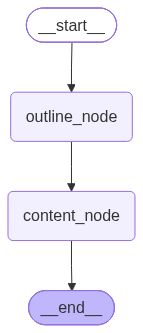

In [15]:
# Graph
graph = StateGraph(BLOGState)

graph.add_node('outline_node', outline_node)
graph.add_node('content_node', content_node)

graph.add_edge(START, 'outline_node')
graph.add_edge('outline_node', 'content_node')
graph.add_edge('content_node', END)

workflow = graph.compile()
workflow

In [16]:
results = workflow.invoke({
    'title': "How to Build a Personal Brand Online: A Complete Beginner's Guide"
})
results

{'title': "How to Build a Personal Brand Online: A Complete Beginner's Guide",
 'outline': "# How to Build a Personal Brand Online: A Complete Beginner's Guide\n\n## Introduction\n\n* **Purpose of the guide** – Explain the value of a personal brand in today’s digital landscape and what readers will achieve by following the steps.  \n* **Target audience** – Early‑career professionals, freelancers, entrepreneurs, and anyone looking to boost their online reputation.  \n* **What to expect** – A clear, step‑by‑step roadmap from identity creation to measurement, with real‑world examples and practical tips.\n\n## H2: 1. Why Personal Branding Matters\n\n* **Key points** – Differentiation in a crowded market, career advancement, authority building, and income potential.  \n* **Examples** – Short case studies of successful personal brands (e.g., a niche blogger, a consultant, a creator).  \n* **Related searches** – “personal branding benefits,” “why build a personal brand.”\n\n## H2: 2. Define Y

In [17]:
print(results['outline'])

# How to Build a Personal Brand Online: A Complete Beginner's Guide

## Introduction

* **Purpose of the guide** – Explain the value of a personal brand in today’s digital landscape and what readers will achieve by following the steps.  
* **Target audience** – Early‑career professionals, freelancers, entrepreneurs, and anyone looking to boost their online reputation.  
* **What to expect** – A clear, step‑by‑step roadmap from identity creation to measurement, with real‑world examples and practical tips.

## H2: 1. Why Personal Branding Matters

* **Key points** – Differentiation in a crowded market, career advancement, authority building, and income potential.  
* **Examples** – Short case studies of successful personal brands (e.g., a niche blogger, a consultant, a creator).  
* **Related searches** – “personal branding benefits,” “why build a personal brand.”

## H2: 2. Define Your Brand Identity

* **Key points** – Core values, mission, vision, and unique value proposition.  
* **H

In [18]:
print(results['content'])

# How to Build a Personal Brand Online: A Complete Beginner’s Guide  

## Introduction  

In today’s hyper‑connected world, who you are online can be as important as what you know. A strong personal brand helps you stand out in a crowded job market, attracts higher‑paying clients, and positions you as a trusted authority in your niche.  

This guide is written for early‑career professionals, freelancers, entrepreneurs, and anyone who wants to turn their online presence into a strategic asset. By following the step‑by‑step roadmap below, you’ll move from a vague idea of “being known” to a concrete, measurable personal brand that works for you—no matter which industry you’re in.  

What you’ll get:  

* A clear process for defining your brand identity.  
* Practical advice on choosing the right digital platforms.  
* A system for creating and repurposing value‑driven content.  
* Tactics for authentic engagement and network growth.  
* Simple metrics to track progress and fine‑tune your 